In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sps
from tqdm import tqdm

# Задача 1. Леди с чаем: точный критерий Фишера

Эта задача показывает, как из правильно спланированного эксперимента получается точный статистический тест. Она появилась после заявления дегустатора о том, что чай с молоком имеет разный вкус в зависимости от порядка наливания. Рональд Фишер использовал этот пример, чтобы объяснить рандомизацию, проверку гипотез и заранее заданное правило принятия решения.

Готовят восемь внешне одинаковых чашек:

- в четырех чашках сначала наливают молоко, затем чай;
- в остальных четырех сначала наливают чай, затем молоко.

Чашки подают в случайном порядке. Участнице заранее сообщают, что чашек каждого типа ровно четыре. После дегустации она должна указать **ровно четыре чашки**, в которых, по ее мнению, молоко было налито первым.

Обозначим через $X$ число правильно найденных чашек из тех четырех, где молоко действительно налили первым. Требуется:

1. выписать распределение $X$ при отсутствии способности различать способы приготовления;
2. найти односторонний $p$-value при $X=4$ и при $X=3$;
3. построить тест с уровнем значимости не выше $5\%$.

## Пункт 1. Гипотезы и нулевая модель

- $H_0$: ответы участницы не связаны с реальным порядком наливания;
- $H_1$: участница различает способы приготовления лучше случайного выбора.

Альтернатива односторонняя: свидетельством способности считаются большие значения $X$. Малое значение $X$ не подтверждает заявленную способность. Если бы нас интересовала любая зависимость, включая систематически перепутанные ответы, потребовалась бы другая альтернатива.

Точнее, при $H_0$ можно зафиксировать любые четыре позиции, выбранные участницей. Из-за случайного порядка настоящие четыре чашки с молоком, налитым первым, равновероятно занимают любой из $C_8^4=70$ наборов позиций. Поэтому не обязательно представлять, будто участница буквально бросает монету. Для теста достаточно, чтобы ее выбор не содержал информации о случайном расположении типов чашек.

Чтобы получить $X=x$, среди четырех выбранных позиций должны оказаться $x$ чашек нужного типа и $4-x$ чашек другого типа. Число таких расположений равно $
C^x_4 \cdot C^{4-x}_4.$

Следовательно, при $H_0$

$$
X\sim\operatorname{Hypergeom}(N=8,K=4,n=4),
$$

$$
\mathbb P_{H_0}(X=x)=\frac{C^x_4\ \cdot C^{4-x}_4}{C_8^4},
\qquad x=0,1,2,3,4.
$$

| $x$ | Число расположений | $\mathbb P_{H_0}(X=x)$ | Всего верных ответов |
|---:|---:|---:|---:|
| 0 | 1 | $1/70$ | 0 |
| 1 | 16 | $16/70$ | 2 |
| 2 | 36 | $36/70$ | 4 |
| 3 | 16 | $16/70$ | 6 |
| 4 | 1 | $1/70$ | 8 |

Проверка знаменателя: $1+16+36+16+1=70=C_8^4$.

## Пункт 2. Таблица 2 на 2 и точный критерий Фишера

Результат эксперимента можно записать как таблицу сопряженности:

| Реальный способ приготовления | Названо: молоко первым | Названо: чай первым | Итого |
|:---|---:|---:|---:|
| Молоко первым | $X$ | $4-X$ | 4 |
| Чай первым | $4-X$ | $X$ | 4 |
| Итого | 4 | 4 | 8 |

Итоги по строкам и столбцам фиксированы устройством эксперимента. При $H_0$ вероятность таблицы определяется значением ее левой верхней ячейки $X$, а эта ячейка имеет гипергеометрическое распределение. Это и есть условная схема точного критерия Фишера для таблицы $2$ на $2$. Слово «точный» означает, что вероятности вычисляются без нормального приближения и без предельных рассуждений.

**Наблюдалось $X=4$**

Для правосторонней альтернативы более экстремальными являются значения не меньше наблюдаемого. При $X=4$ большего значения нет, поэтому

$$
p=\mathbb P_{H_0}(X\ge4)=\frac1{70}\approx0.0143.
$$

Полностью правильная классификация статистически значима на уровне $5\%$.

**Наблюдалось $X=3$**

В хвост входят результат $X=3$ и еще более сильный результат $X=4$:

$$
p=\mathbb P_{H_0}(X\ge3)
=\frac{16+1}{70}
=\frac{17}{70}
\approx0.2429.
$$

При уровне $5\%$ этот результат не позволяет отклонить $H_0$. Брать только $\mathbb P(X=3)=16/70$ неправильно: $p$-value включает наблюдаемый результат и все результаты, которые как минимум столь же убедительны в направлении выбранной альтернативы.

## Пункт 3. Воспроизводимая проверка

Перебираем все $C_8^4=70$ возможных наборов позиций для четырех чашек нужного типа. Это исчерпывающая проверка, а не симуляция, поэтому результат не зависит от генератора случайных чисел.

In [ ]:
from math import comb

Считаем вероятности через биномиальные коэффициенты: X — число выбранных пакетов с молоком среди 4 из 8, причём "с молоком" ровно 4 пакета, "без молока" тоже 4.

In [ ]:
n = 4  # выбираем 4 пакета
milk = 4  # из них могут быть с молоком (0..4)
total = comb(8, 4)  # всего способов

In [ ]:
# P(X = k) = C(4, k) * C(4, 4-k) / C(8, 4)
p = [comb(4, k) * comb(4, 4 - k) / total for k in range(5)]

print("Число вариантов для X = 0, 1, 2, 3, 4:", [round(pi * total) for pi in p])
print("Всего вариантов:", total)
print(f"P(X = 4) = {p[4]} = {p[4]:.6f}")
print(f"P(X >= 3) = {p[3] + p[4]} = {p[3] + p[4]:.6f}")

Число вариантов для X = 0, 1, 2, 3, 4: [1, 16, 36, 16, 1]
Всего вариантов: 70
P(X = 4) = 0.014285714285714285 = 0.014286
P(X >= 3) = 0.24285714285714285 = 0.242857


**Итог**

При уровне значимости $5\%$ правило решения имеет вид

$$
\text{отклонить }H_0\text{ только при }X=4.
$$

При $X=4$ получаем $p=1/70\approx0.0143$ и отклоняем $H_0$. При $X=3$ получаем $p=17/70\approx0.2429$ и не отклоняем $H_0$.

# Задача 2. Подозрительный балансировщик

Сервис распределяет запросы между десятью одинаковыми серверами. По заявленному алгоритму для каждого запроса сервер выбирается независимо и равновероятно.

После обновления возникло подозрение, что запросы слишком часто попадают на один и тот же сервер. До просмотра результатов решили проверить одну серию из четырех последовательных запросов.

Рассмотрим два возможных результата. Числа обозначают номера серверов:

- результат A: `3, 3, 7, 3`;
- результат B: `3, 7, 3, 7`.

Нас интересует концентрация запросов на любом сервере: конкретный сервер заранее не выбран.

**Требуется:**

1. Выбрать статистику, большие значения которой свидетельствуют об избыточной концентрации запросов.
2. Вывести её распределение при заявленном алгоритме.
3. Найти односторонний $p$-value для результатов A и B.
4. Построить критерий с уровнем значимости не выше $5\%$.

## Пункт 1. Гипотезы и статистика

- $H_0$: сервер для каждого запроса выбирается независимо, вероятность выбора каждого из десяти серверов равна $1/10$.
- $H_1$: запросы концентрируются на одном сервере сильнее, чем предусмотрено этой моделью.

Обозначим через $N_j$ число запросов, направленных на сервер $j$. Выберем статистику — максимальное число запросов на одном сервере:

$$T=\max(N_1,\ldots,N_{10}).$$

Возможные значения: $T\in\{1,2,3,4\}$.

- При $T=1$ все четыре запроса попали на разные серверы.
- При $T=4$ все четыре запроса попали на один сервер.

Большие значения $T$ свидетельствуют в пользу выбранной альтернативы. Для результата A наблюдаем $T=3$, для результата B — $T=2$.

## Пункт 2. Распределение статистики при нулевой гипотезе

Каждый из четырех запросов может попасть на любой из десяти серверов. При $H_0$ все упорядоченные последовательности равновероятны, их число равно

$$10^4=10000.$$

Обозначим через $a_t$ число последовательностей, для которых $T=t$.

**Случай $T=1$.** Все серверы разные: для первого запроса доступны десять серверов, для второго — девять, для третьего — восемь, для четвертого — семь.

$$a_1=10\cdot9\cdot8\cdot7=5040.$$

**Случай $T=4$.** Все запросы направлены на один сервер. Остается выбрать этот сервер:

$$a_4=10.$$

**Случай $T=3$.** Выбираем сервер для трех запросов, три позиции этих запросов в последовательности и другой сервер для оставшегося запроса:

$$a_3=10\cdot C_4^3\cdot9=10\cdot4\cdot9=360.$$

**Случай $T=2$.** Это все оставшиеся последовательности, поскольку значения $1,2,3,4$ исчерпывают возможные значения статистики:

$$a_2=10000-5040-360-10=4590.$$

Вероятность каждого значения статистики равна доле соответствующих последовательностей:

$$\mathbb{P}_{H_0}(T=t)=\frac{a_t}{10000},\qquad t=1,2,3,4.$$

| $t$ | Распределение четырех запросов между занятыми серверами | $a_t$ | $\mathbb{P}_{H_0}(T=t)$ |
|---:|:---|---:|---:|
| 1 | $1+1+1+1$ | 5040 | 0.504 |
| 2 | $2+1+1$ или $2+2$ | 4590 | 0.459 |
| 3 | $3+1$ | 360 | 0.036 |
| 4 | $4$ | 10 | 0.001 |

Проверка: $5040+4590+360+10=10000$, сумма вероятностей равна единице.

In [ ]:
from math import comb

total = 10 ** 4

counts = {
    1: 10 * 9 * 8 * 7,
    3: 10 * comb(4, 3) * 9,
    4: 10
}
counts[2] = total - sum(counts.values())
probs = {t: counts[t] / total for t in range(1, 5)}

for t, prob in probs.items():
    print(f"T = {t}: {counts[t]} исходов, вероятность = {prob:.3f}")

print(f"Сумма вероятностей: {sum(probs.values()):.3f}")

T = 1: 5040 исходов, вероятность = 0.504
T = 2: 4590 исходов, вероятность = 0.459
T = 3: 360 исходов, вероятность = 0.036
T = 4: 10 исходов, вероятность = 0.001
Сумма вероятностей: 1.000


## Пункт 3. Односторонний p-value

Свидетельством против $H_0$ считаются большие значения $T$. Поэтому складываем вероятности наблюдаемого значения и всех больших значений:

$$p=\mathbb{P}_{H_0}(T\ge t_{\text{набл}}).$$

**Результат A: `3, 3, 7, 3`.** На один сервер попали три запроса, поэтому $T=3$.

$$p=\mathbb{P}_{H_0}(T\ge3)=\frac{360+10}{10000}=0.037.$$

При уровне значимости $5\%$ отклоняем $H_0$: такая или более сильная концентрация маловероятна при заявленном алгоритме.

**Результат B: `3, 7, 3, 7`.** Максимальное число запросов на одном сервере равно двум, поэтому $T=2$.

$$p=\mathbb{P}_{H_0}(T\ge2)=\frac{4590+360+10}{10000}=0.496.$$

Оснований отклонить $H_0$ на уровне $5\%$ нет.

Для результата A нельзя брать только $\mathbb{P}_{H_0}(T=3)=0.036$: в $p$-value также входит более сильная концентрация $T=4$.

In [ ]:
samples = {
    "A": [3, 3, 7, 3],
    "B": [3, 7, 3, 7]
}

for name in samples:
    servers = samples[name]

    # Считаем запросы на каждом из десяти серверов
    load = [0] * 10
    for server in servers:
        load[server - 1] += 1

    t_obs = max(load)

    # Складываем вероятности T >= наблюдаемого значения
    p_value = 0
    for t in range(t_obs, 5):
        p_value += probs[t]

    print(f"{name}: T = {t_obs}, p-value = {p_value:.3f}")
    if p_value <= 0.05:
        print("Отклоняем H0")
    else:
        print("Не отклоняем H0")

A: T = 3, p-value = 0.037
Отклоняем H0
B: T = 2, p-value = 0.496
Не отклоняем H0


## Пункт 4. Критическая область и уровень значимости

Ищем правило вида «отклонить $H_0$, если $T\ge c$».

Порог $c=3$ подходит:

$$\mathbb{P}_{H_0}(T\ge3)=0.037\le0.05.$$

Порог $c=2$ уже не подходит:

$$\mathbb{P}_{H_0}(T\ge2)=0.496>0.05.$$

Поэтому правило решения имеет вид:

$$\text{отклонить }H_0\text{, если }T\ge3.$$

То есть отклоняем $H_0$, если хотя бы три из четырех запросов попали на один сервер.

Фактический уровень значимости этого критерия равен $3.7\%$. При правильном алгоритме он будет ошибочно отклонять $H_0$ в среднем в $3.7\%$ таких экспериментов.

Это точный критерий: его вероятности получены непосредственно из нулевой модели, без нормального приближения.

## Пункт 5. Воспроизводимая проверка

Переберем все $10000$ упорядоченных последовательностей из четырех номеров серверов. Для каждой вычислим $T$ и посчитаем, сколько раз встречается каждое значение.

Это полный перебор, а не симуляция. Полученные числа должны совпасть с распределением, выведенным вручную.

In [ ]:
counts_check = {1: 0, 2: 0, 3: 0, 4: 0}

for server_1 in range(1, 11):
    for server_2 in range(1, 11):
        for server_3 in range(1, 11):
            for server_4 in range(1, 11):
                servers = [server_1, server_2, server_3, server_4]

                # Считаем запросы на каждом сервере
                load = [0] * 10
                for server in servers:
                    load[server - 1] += 1

                # Находим статистику и учитываем этот исход
                t = max(load)
                counts_check[t] += 1

print("Число исходов:", counts_check)
print("Совпадает с расчетом:", counts_check == counts)

Число исходов: {1: 5040, 2: 4590, 3: 360, 4: 10}
Совпадает с расчетом: True


# Задача 3. Золотая жила



In [ ]:
def ztest_1sample(pop_mean, sample_mean, sample_std, sample_size, alternative='two-sided'):
    statistic = (sample_mean - pop_mean)/(sample_std / sample_size**0.5)
    if alternative == 'less':
        pvalue = sps.norm.cdf(statistic)
    if alternative == 'greater':
        pvalue = 1 - sps.norm.cdf(statistic)
    if alternative == 'two-sided':
        pvalue = 2 * (1 - sps.norm.cdf(abs(statistic)))
    return statistic, pvalue

def ztest_1sample_data(pop_mean, sample, alternative='two-sided'):
    return ztest_1sample(pop_mean, sample_mean=sample.mean(),
                         sample_std=sample.std(), sample_size=len(sample),
                         alternative=alternative)

In [ ]:
def ztest_2sample(sample1_mean, sample2_mean, sample1_std, sample2_std, sample1_size, sample2_size, alternative='two-sided'):
    statistic = (sample1_mean - sample2_mean)/(sample1_std**2 / sample1_size + sample2_std**2 / sample2_size)**0.5
    if alternative == 'less':
        pvalue = sps.norm.cdf(statistic)
    if alternative == 'greater':
        pvalue = 1 - sps.norm.cdf(statistic)
    if alternative == 'two-sided':
        pvalue = 2 * (1 - sps.norm.cdf(abs(statistic)))
    return statistic, pvalue

def ztest_2sample_data(sample1, sample2, alternative='two-sided'):
    return ztest_2sample(
        sample1_mean=sample1.mean(), sample2_mean=sample2.mean(),
        sample1_std=sample1.std(), sample2_std=sample2.std(),
        sample1_size=len(sample1), sample2_size=len(sample2),
        alternative=alternative
    )

Датасет [golden_mine.csv](https://raw.githubusercontent.com/zalig/cu-datasets/main/golden_mine.csv) содержит данные для нахождения наиболее прибыльных категорий клиентов — пользователей
платформы для изучения иностранного языка.

Описание столбцов датасета:

- Gender – пол клиента;
- Age — возраст клиента в годах;
- Age Group — возрастная группа;
- Payments — общая сумма платежей от игрока в рублях за всё время существования платформы;
- Costs — себестоимость оказанных клиенту услуг в рублях за всё время существования платформы;
- Profit — разница между Payments и Costs.

Стоимость привлечения нового клиента $15000$ рублей.
Считай, что текущие клиенты — это выборка из всех возможных клиентов.

Если тесты проводятся серией, используй $5\%$ уровень значимости для всей серии.

Для определения минимально детектируемого эффекта используй мощность $80\%$.



1. Найди среднюю прибыль от привлечения клиента без таргетирования и проверь, что она статистически значимо больше нуля. Прокомментируй также экономическую значимость.

2. Для двух категорий клиентов: «Мужчины 18-24 лет» и «Женщины 18-24 лет» проверь статистическую значимость разницы между ними в прибыльности. Прокомментируй также экономическую значимость.

3. Проведи тесты значимости прибыльности привлечения клиентов в каждой из двух категорий «Мужчины 18-24 лет» и «Женщины 18-24 лет» по отдельности. На каком уровне значимости сделаны выводы?

4. Проведи тесты значимости прибыльности привлечения клиентов в каждой из двух категорий «Женщины 18-21 лет» и «Женщины 22-24 лет» по отдельности, статистическую значимость разницы между категориями. Объясни выбор уровня значимости.

5. Прокомментируй идею сравнивать подкатегории «Женщины 18 лет», «Женщины 19 лет», «Женщины 20 лет»,... «Женщины 24 лет», попарно тестируя значимость разницы в прибыльности:
 - Как придётся выбирать уровень значимости? Почему нельзя взять 5% на каждый тест?
 - Что произойдёт с минимальным детектируемым эффектом? Качественного ответа достаточно.

6. Определи минимальный детектируемый эффект в тесте, проверяющем, что прибыль в категории «Мужчины 18 лет» выше стоимости привлечения. Определи минимальный детектируемый эффект в серии тестов, проверяющих, что прибыль хотя бы в одной из категорий в категории «Мужчины 18 лет», «Мужчины 19 лет»,... «Мужчины 24 года» выше стоимости привлечения. Не забывай про корректировку уровня значимости.

7. Проверь значимость разницы в прибыльности категории «Золотая жила» (найдена в кейсе-1) и категории «Женщины 18-24 лет».



## Пункт 1. Средняя прибыль от привлечения клиента

Найди среднюю прибыль от привлечения клиента без таргетирования и проверь, что она статистически значимо больше нуля. Прокомментируй также экономическую значимость.





**Решение**

Загрузим данные, проведём необходимую предобработку и воспользуемся z-тестом для проверки гипотезы.

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/zalig/cu-datasets/main/golden_mine.csv')
df['Gender'] = df['Gender'].astype('string')
df['AgeGroup'] = df['AgeGroup'].astype('string')
df['Gender'] = df['Gender'].astype('string').str.lower()
df.head()

,Payments,Costs,Profit,Age,Gender,AgeGroup
0,9400,8100,1300,19,male,18-24
1,26600,13900,12700,29,male,25-39
2,9750,6750,3000,20,male,18-24
3,29700,11200,18500,18,female,18-24
4,49700,10450,39250,21,female,18-24


In [ ]:
# средняя прибыль от привлечения клиента без таргетирования

mean_profit = df['Profit'].mean()
attraction_profit = mean_profit - 15000
attraction_profit

407.24612736660856

Проверим гипотезу: <br>
$H_0: \mu = 0$ - средняя прибыль от привлечения без таргетирования равна нулю, <br>
$H_1: \mu > 0$ - средняя прибыль больше нуля.

In [ ]:
ztest_1sample_data(pop_mean=0, sample=df['Profit'] - 15000, alternative='greater')

(0.29911859168977245, 0.3824247806053167)

Из результатов теста следует, что $H_0$ не отвергается (pvalue > 0.05): нет достаточных статистических доказательств, чтобы считать прибыль от привлечения клиентов без таргетирования большей нуля. <br>
Экономически такой результат заставляет задуматься о таргетировании или отказаться от привлечения клиентов в целом.

## Пункт 2. Сравнение молодых мужчин и молодых женщин

Для двух категорий клиентов: «Мужчины 18-24 лет» и «Женщины 18-24 лет» проверь статистическую значимость разницы между ними в прибыльности. Прокомментируй также экономическую значимость.



**Решение**

Сначала выделим обе категории в отдельные датафреймы, а затем проведём двух-выборочный двусторонний z-тест для проверки гипотезы: <br>
$H_0: \mu_A = \mu_B$ - средняя прибыль в первой категории совпадает со средней прибылью во второй категории, <br>
$H_1: \mu_A \neq \mu_B$ - средняя прибыль в первой категории не равняется средней прибыли во второй категории.

In [ ]:
man_18_24 = df[(df['Gender'] == 'male') & (df['Age'] <= 24)].copy()
woman_18_24 = df[(df['Gender'] == 'female') & (df['Age'] <= 24)].copy()

In [ ]:
man_18_24['Profit'].mean() - woman_18_24['Profit'].mean()

-13122.611458360896

In [ ]:
ztest_2sample_data(sample1=man_18_24['Profit'], sample2=woman_18_24['Profit'], alternative='two-sided')

(-27.09280730417151, 0.0)

pvalue = 0, следовательно $H_0$ отвергается и разница в прибыльности между этими двумя категориями статистически значима и составляет в среднем 13825 в пользу женщин. <br>
Экономически можно сделать вывод о том, что при выборе из данных таргетов не стоит выбирать мужской сегмент. Также, возможно, стоит выполнить более тщательное таргетирование и выделить прибыльную группу мужчин или женщин.

## Пункт 3. Средняя прибыль в сегментах молодых женщин и молодых мужчин

Проведи тесты значимости прибыльности привлечения клиентов в каждой из двух категорий «Мужчины 18-24 лет» и «Женщины 18-24 лет» по отдельности. На каком уровне значимости сделаны выводы?



**Решение**

Сформулируем гипотезы для этих тестов: <br>
$H_0: \mu = 0$ - средняя прибыль от привлечения клиентов равна нулю, <br>
$H_1: \mu > 0$ - средняя прибыль от привлечения клиентов положительная.

Данные статистические тесты являются независимыми, поэтому не будем проводить корректировку уровня значимости.

In [ ]:
ztest_1sample_data(pop_mean=0, sample=man_18_24['Profit'] - 15000, alternative='greater')

(-4.065077065970155, 0.9999759917034207)

In [ ]:
ztest_1sample_data(pop_mean=0, sample=woman_18_24['Profit'] - 15000, alternative='greater')

(66.48342590449388, 0.0)

pvalue $\approx$ 1 для теста с группой мужчин и равняется 0 для теста с группой женщин. <br>
Следовательно, гипотеза $H_0$ для мужчин не отвергается (нет достаточных статистических доказательство того, что средняя прибыль не равняется нулю), а для женщин отвергается (есть достаточно статистических доказательств, что прибыль положительна).

## Пункт 4. Средняя прибыль в подкатегориях молодых женщин

Проведи тесты значимости прибыльности привлечения клиентов в каждой из двух категорий «Женщины 18-21 лет» и «Женщины 22-24 лет» по отдельности, статистическую значимость разницы между категориями. Объясни выбор уровня значимости.



**Решение**

Для проведения данных тестов применим коррекцию уровня значимости: поделим исходный уровень значимости для серии тестов ($5\%$) на количество тестов ($3$) в связи с тем, что серия состоит из зависимых тестов, что увеличивает вероятность ложноположительных результатов. Такая коррекция позволит контролировать общий уровень значимости для серии тестов. <br>
Итоговый уровень значимости:

In [ ]:
0.05 / 3.0

0.016666666666666666

In [ ]:
woman_18_21 = df[(df['Gender'] == 'female') & (df['Age'] <= 21)].copy()
woman_22_24 = df[(df['Gender'] == 'female') & (df['Age'] >= 22) & (df['Age'] <= 24)].copy()

Аналогичные гипотезы для одновыборочных тестов: <br>
$H_0: \mu = 0$ - средняя прибыль от привлечения клиентов для данной группы равна нулю, <br>
$H_1: \mu > 0$ - средняя прибыль от привлечения клиентов для данной группы положительная.

In [ ]:
ztest_1sample_data(pop_mean=0, sample=woman_18_21['Profit'] - 15000, alternative='greater')

(59.57084569971796, 0.0)

In [ ]:
ztest_1sample_data(pop_mean=0, sample=woman_22_24['Profit'] - 15000, alternative='greater')

(32.50075312037019, 0.0)

Для двух-выборочного теста гипотеза формулируется так: <br>
$H_0: \mu_1 = \mu_2$ - средняя прибыль первой категории совпадает со средней прибылью второй категории, <br>
$H_1: \mu_1 \neq \mu_2$ - средняя прибыль первой категории не равняется средней прибыли второй категории.

In [ ]:
ztest_2sample_data(sample1=woman_18_21['Profit'], sample2=woman_22_24['Profit'], alternative='two-sided')

(-8.481210212854762, 0.0)

pvalue = 0 для всех тестов, следовательно есть достаточно статистических доказательств того, что привлечение каждой из этих групп принесет положительную прибыль, при этом средние значения прибыли отличаются. <br>
Можно сделать вывод, что одна из этих групп прибыльнее другой и продолжить анализ этой конкретной группы.

## Пункт 5. Средняя прибыль в микро-подсегментах молодых женщин

Прокомментируй идею сравнивать подкатегории «Женщины 18 лет», «Женщины 19 лет», «Женщины 20 лет»,... «Женщины 24 лет», попарно тестируя значимость разницы в прибыльности.

 - Как придётся выбирать уровень значимости? Почему нельзя взять 5% на каждый тест?
 - Что произойдёт с минимальным детектируемым эффектом?



**Решение**

С учётом того, что прошлые тесты показали положительный эффект от привлечения группы "Женщины 18-24 лет" и различия в средней прибыли в подкатегориях, тестирование для более маленьких подгрупп является хорошим решением. <br>
Здесь мы тоже имеем дело с зависимыми тестами в серии тестов, поэтому применим коррекцию уровня значимости 0.05 на общее количество тестов 28

In [ ]:
0.05 / 28.0

0.0017857142857142859

Проверяемые гипотезы аналогичны предыдущему заданию.

In [ ]:
woman_18 = df[(df['Gender'] == 'female') & (df['Age'] == 18)].copy()
woman_19 = df[(df['Gender'] == 'female') & (df['Age'] == 19)].copy()
woman_20 = df[(df['Gender'] == 'female') & (df['Age'] == 20)].copy()
woman_21 = df[(df['Gender'] == 'female') & (df['Age'] == 21)].copy()
woman_22 = df[(df['Gender'] == 'female') & (df['Age'] == 22)].copy()
woman_23 = df[(df['Gender'] == 'female') & (df['Age'] == 23)].copy()
woman_24 = df[(df['Gender'] == 'female') & (df['Age'] == 24)].copy()

all_groups_woman = [woman_18, woman_19, woman_20, woman_21, woman_22, woman_23, woman_24]

In [ ]:
for idx, group in enumerate(all_groups_woman):
    print("Одновыборочный тест для группы", idx + 1, ':', ztest_1sample_data(pop_mean=0, sample=group['Profit'] - 15000, alternative='greater'))
    for innerIdx, innergroup in list(enumerate(all_groups_woman[idx + 1:])):
        print("Двух-выборочный тест для групп", idx + 1, 'и', idx + innerIdx + 2, ':', ztest_2sample_data(sample1=group['Profit'], sample2=innergroup['Profit'], alternative='two-sided'))

Одновыборочный тест для группы 1 : (41.506472972351325, 0.0)
Двух-выборочный тест для групп 1 и 2 : (-0.8253324448037017, 0.40918287665684927)
Двух-выборочный тест для групп 1 и 3 : (-0.4556451043738604, 0.6486452031567398)
Двух-выборочный тест для групп 1 и 4 : (-8.521685474019227, 0.0)
Двух-выборочный тест для групп 1 и 5 : (-6.831153904481396, 8.423484132435988e-12)
Двух-выборочный тест для групп 1 и 6 : (-5.7779482049483315, 7.561707704439868e-09)
Двух-выборочный тест для групп 1 и 7 : (-5.306294601405896, 1.1187609350038485e-07)
Одновыборочный тест для группы 2 : (33.071637031452454, 0.0)
Двух-выборочный тест для групп 2 и 3 : (-0.19634773823899843, 0.8443379988033635)
Двух-выборочный тест для групп 2 и 4 : (-7.519686570035113, 5.484501741648273e-14)
Двух-выборочный тест для групп 2 и 5 : (-6.077736667089465, 1.2189069753532067e-09)
Двух-выборочный тест для групп 2 и 6 : (-5.470881134412882, 4.478035742216946e-08)
Двух-выборочный тест для групп 2 и 7 : (-4.7671329160074585, 1.8686

По результатам тестов видно, что каждая из групп по отдельности показывает положительный эффект от привлечения ($H_0$ отвергается при pvalue = 0), при этом большая часть имеют статистически неразличимую прибыльность ($H_0$ не отвергается при уровне значимости 0.00179).

Минимально детектируемый эффект в серии тестов может как увеличиться, так и уменьшиться, так как с одной стороны более строгие критерии значимости (уровень значимости уменьшается в 28 раз) требуют более выраженных эффектов для того, чтобы быть признанными статистически значимыми, а с другой разные группы имеют разные $sigma$ и размеры, что может привести к уменьшению MDE.

## Пункт 6. Расчёт MDE в подкатегориях молодых мужчин

Определи минимальный детектируемый эффект в тесте, проверяющем, что прибыль в категории «Мужчины 18 лет» выше стоимости привлечения.

Определи минимальный детектируемый эффект в серии тестов, проверяющих, что прибыль хотя бы в одной из категорий в категории «Мужчины 18 лет», «Мужчины 19 лет»,... «Мужчины 24 года» выше стоимости привлечения. Не забывай про корректировку уровня значимости.



**Решение**

Для определеления минимально детектируемого эффекта будем использовать метод Монте-Карло методом Монте-Карло. Для определения эффекта берём мощность $80\%$ из условия задачи.

Гипотеза, проверяемая в одновыборочном тесте: <br>
$H_0: \mu_{18} = 15000$ - средняя прибыль равняется стоимости привлечения, <br>
$H_1: \mu_{18} > 15000$ - средняя прибыль больше стоимости привлечения.

In [ ]:
man_18 = df[(df['Gender'] == 'male') & (df['Age'] == 18)].copy()

In [ ]:
# переопределим функцию поиска мощности под односторонний тест с данными

def zpower_1sample_data_monte_carlo(mu0, mu, sigma, sample_size, n_monte_carlo, significance_level=0.05):
    rejections = 0

    for _ in range(n_monte_carlo):
        sample = sps.norm.rvs(loc=mu, scale=sigma, size=sample_size)
        test_stat, pvalue = ztest_1sample(pop_mean=mu0, sample_mean=sample.mean(),
                                          sample_std=sample.std(), sample_size=len(sample), alternative='greater')
        if pvalue < significance_level:
            rejections += 1

    return rejections / n_monte_carlo

In [ ]:
for effect in np.arange(0, 1000, 10):
    if zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_18['Profit'].std(), sample_size=len(man_18['Profit']), n_monte_carlo=1000) >= 0.8:
        print('Минимально детектируемый эффект:', effect)
        break

Минимально детектируемый эффект: 150


In [ ]:
ztest_1sample(15000, 15150, man_18['Profit'].std(), len(man_18['Profit']), alternative='greater')

(2.573825402327695, 0.005029050788628253)

Полученный минимально детектируемый эффект означает, что в данном тесте различие между средними будет обнаружено с 80% вероятностью, если оно будет $\geq 150$. Меньшие различия будут детектироваться тестом с вероятностью $<80\%$.

Для серии тестов "прибыль хотя бы в одной из категорий в категории «Мужчины 18 лет», «Мужчины 19 лет»,... «Мужчины 24 лет» выше стоимости привлечения" скорректируем уровень значимости на количество тестов в серии: $0.00714$ вместо $0.05$.

In [ ]:
0.05 / 7.0

0.0071428571428571435

In [ ]:
man_18 = df[(df['Gender'] == 'male') & (df['Age'] == 18)].copy()
man_19 = df[(df['Gender'] == 'male') & (df['Age'] == 19)].copy()
man_20 = df[(df['Gender'] == 'male') & (df['Age'] == 20)].copy()
man_21 = df[(df['Gender'] == 'male') & (df['Age'] == 21)].copy()
man_22 = df[(df['Gender'] == 'male') & (df['Age'] == 22)].copy()
man_23 = df[(df['Gender'] == 'male') & (df['Age'] == 23)].copy()
man_24 = df[(df['Gender'] == 'male') & (df['Age'] == 24)].copy()

all_groups_man = [man_18, man_19, man_20, man_21, man_22, man_23, man_24]

In [ ]:
for effect in np.arange(0, 1000, 10):
    if zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_18['Profit'].std(), sample_size=len(man_18['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_19['Profit'].std(), sample_size=len(man_19['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_20['Profit'].std(), sample_size=len(man_20['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_21['Profit'].std(), sample_size=len(man_21['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_22['Profit'].std(), sample_size=len(man_22['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_23['Profit'].std(), sample_size=len(man_23['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8 \
    or zpower_1sample_data_monte_carlo(mu0=15000, mu=15000 + effect, sigma=man_24['Profit'].std(), sample_size=len(man_24['Profit']), n_monte_carlo=1000, significance_level=0.05 / 7) >= 0.8:
        print('Минимально детектируемый эффект:', effect)
        break

Минимально детектируемый эффект: 200


Минимально детектируемый эффект для выбранных групп около $200$ (результат стал больше из-за корректировки уровня значимости). Значит, при исследовании всех групп одновременно различие между средними будет обнаружено с $80\%$ вероятностью, если оно будет $\geq 200$. Меньшие различия будут детектироваться тестом с вероятностью $<80\%$.

## Пункт 7. Сравнение мужчин и женщин в подкатегории молодых

Проверь значимость разницы в прибыльности категории «Мужчины 21-24 года» и категории «Женщины 18-24 лет».

**Решение**

Категория "Золотая жила" - это "Мужчины 21-24 года". Проведём двух-выборочный z-тест: <br>
$H_0: \mu_1 = \mu_2$ - средняя прибыльность категории "Золотая жила" не отличается от средней прибыльности категории "Женщины 18-24 лет", <br>
$H_0: \mu_1 \neq \mu_2$ - средняя прибыльность различается.

In [ ]:
man_21_24 = df[(df['Gender'] == 'male') & (df['Age'] >= 21) & (df['Age'] <= 24)].copy()
woman_18_24 = df[(df['Gender'] == 'female') & (df['Age'] <= 24)].copy()

In [ ]:
ztest_2sample_data(sample1=man_21_24['Profit'], sample2=woman_18_24['Profit'], alternative='two-sided')

(100.56723036478428, 0.0)

pvalue = 0, следовательно $H_0$ отвергается и есть достаточно статистических доказательств, чтобы считать среднюю прибыльность категории "Золотая жила" не равной средней прибыльности категории "Женщины 18-24 лет".

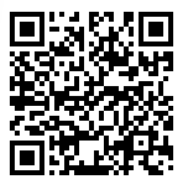